#### Phase 2: Predictive ML Modeling 

##### Task 2.1: Build a supervised text classification model

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [5]:
df = pd.read_csv("jan_samadhan_cleaned.csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (490, 8)


,Complaint_ID,State,Department,Complaint_Date,Complaint_Description,Status,Resolution_Date,Complaint_Month
0,GRV0001,Haryana,Electricity,2026-09-28,frequent electricity cuts in village,Pending,NaN,2026-09
1,GRV0002,Haryana,Health,2026-08-03,medicine shortage in government hospital,Resolved,2026-08-27,2026-08
2,GRV0003,Punjab,Health,2026-05-11,medicine shortage in government hospital,Resolved,2026-05-13,2026-05
3,GRV0004,Himachal Pradesh,Health,2026-07-11,medicine shortage in government hospital,In Progress,NaN,2026-07
4,GRV0005,Delhi,Water Supply,2026-09-10,no drinking water supply for several days,Resolved,2026-09-27,2026-09


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Use complete dataset
X = df["Complaint_Description"].fillna("")
y = df["Department"]

# Convert text into numerical features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=1000,
    ngram_range=(1, 2)
)

X_tfidf = vectorizer.fit_transform(X)

# Train model using all rows
model = LogisticRegression(max_iter=1000, random_state=42)

model.fit(X_tfidf, y)

print("Model trained on:", len(df), "records")

Model trained on: 490 records


In [7]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_tfidf)

print("Training Accuracy:", accuracy_score(y, y_pred))

print(classification_report(y, y_pred))

Training Accuracy: 1.0
                precision    recall  f1-score   support

     Education       1.00      1.00      1.00        66
   Electricity       1.00      1.00      1.00        95
        Health       1.00      1.00      1.00       106
       Revenue       1.00      1.00      1.00        28
Road Transport       1.00      1.00      1.00        57
Social Welfare       1.00      1.00      1.00        43
  Water Supply       1.00      1.00      1.00        95

      accuracy                           1.00       490
     macro avg       1.00      1.00      1.00       490
  weighted avg       1.00      1.00      1.00       490



In [8]:
complaint = [
    "There is no drinking water supply in our village"
]

complaint_tfidf = vectorizer.transform(complaint)

prediction = model.predict(complaint_tfidf)

print("Predicted Department:", prediction[0])

Predicted Department: Water Supply


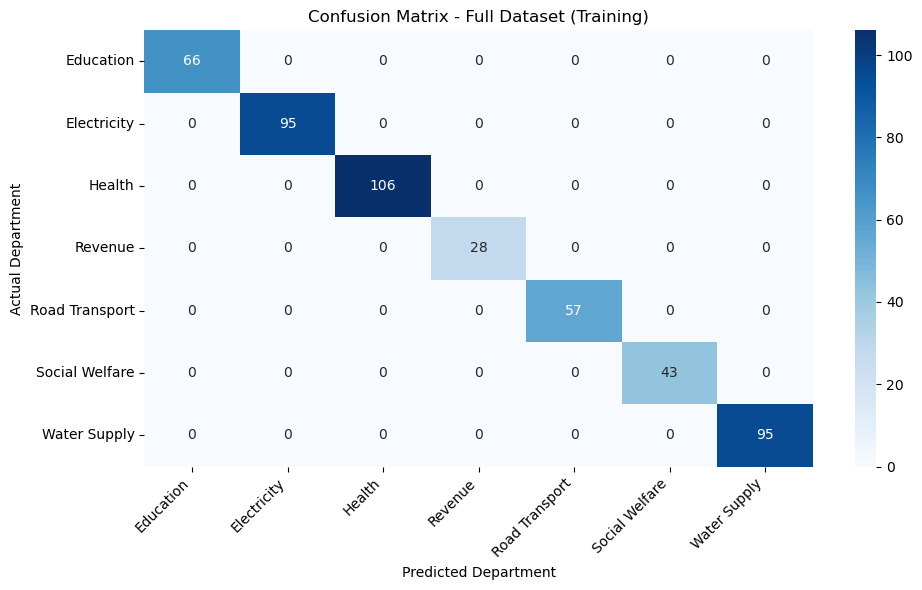

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y, y_pred, labels=model.classes_)

plt.figure(figsize=(10, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Department")
plt.ylabel("Actual Department")
plt.title("Confusion Matrix - Full Dataset (Training)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [10]:
import joblib

joblib.dump(model, "jan_samadhan_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

##### Task 2.3: Conceptual Check

`Why was Logistic Regression chosen over Deep Learning?`

Logistic Regression was selected because it is lightweight, computationally efficient, and performs well on text classification tasks when combined with TF-IDF features. The prototype uses a small dataset of approximately 500 grievance records, which is insufficient to reliably train a large Deep Neural Network or BERT model from scratch. Logistic Regression requires less training time, memory, and computational resources while providing interpretable predictions. Therefore, it is a practical choice for developing and evaluating the initial Jan-Samadhan grievance-routing prototype.